# Seasonal adjustment

In [1]:
# Setup: install the toolkit when running on Google Colab, and a plotting style
import sys

if "google.colab" in sys.modules:
    %pip install -q "econts[book] @ git+https://github.com/hmorao95/econ-time-series-manual"

import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

A seasonally adjusted (SA) series removes the movements that repeat every
year at the same time (Christmas sales, summer construction, school-year
hiring) so that what remains is trend, cycle and irregular news.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL, MSTL, seasonal_decompose
from econts import load

nsa = load("RSXFSN").asfreq("MS")  # retail sales, not seasonally adjusted
sa_official = load("RSXFS").asfreq("MS")
y = np.log(nsa)

## Is there seasonality?

Look at the average by calendar month of the detrended series, and at the
autocorrelation at the seasonal lag.

In [3]:
growth = 100 * y.diff()
by_month = growth.groupby(growth.index.month).mean().round(1)
print(by_month.to_string())  # December +15%, January -20%
print("ACF at lag 12:", round(sm.tsa.acf(growth.dropna(), nlags=12)[12], 2))

date
1    -25.4
2     -0.9
3     13.1
4     -1.7
5      5.9
6     -2.3
7      0.2
8      2.1
9     -6.4
10     3.4
11     1.9
12    14.6
ACF at lag 12: 0.92


A quick formal test: regress the growth rate on month dummies and test that
they are jointly equal (an F-test).

In [4]:
df = pd.DataFrame({"g": growth, "month": growth.index.month}).dropna()
ols = sm.formula.ols("g ~ C(month)", data=df).fit()
print(f"F = {ols.fvalue:.0f}, p = {ols.f_pvalue:.1e}")

F = 408, p = 4.4e-211


## Classical decomposition

`seasonal_decompose` is the textbook method: a centered moving average for
the trend and fixed seasonal factors. Simple, but the seasonal pattern cannot
change over time and the trend is missing at both ends.

In [5]:
classic = seasonal_decompose(nsa, model="multiplicative", period=12)
sa_classic = nsa / classic.seasonal
print(classic.seasonal["2024"].round(3).to_string())

date
2024-01-01    0.898
2024-02-01    0.886
2024-03-01    1.008
2024-04-01    0.986
2024-05-01    1.042
2024-06-01    1.014
2024-07-01    1.012
2024-08-01    1.031
2024-09-01    0.963
2024-10-01    0.993
2024-11-01    1.008
2024-12-01    1.162
Freq: MS


## STL

STL (Cleveland et al., 1990) lets the seasonal pattern evolve, has no end
point loss and, with `robust=True`, downweights outliers such as the 2020
lockdowns, so they do not contaminate the seasonal factors.

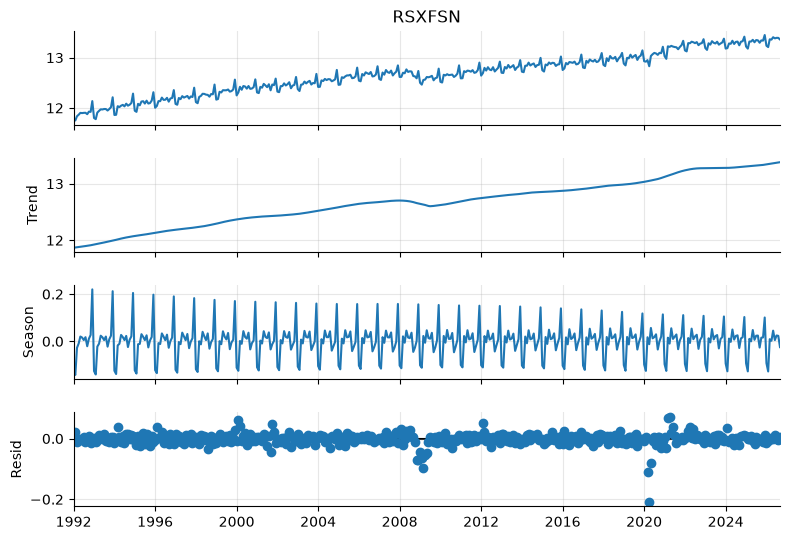

In [6]:
stl = STL(y, period=12, seasonal=13, robust=True).fit()
sa_stl = np.exp(y - stl.seasonal)

fig = stl.plot()
fig.set_size_inches(8, 6)

Main knobs: `seasonal` (odd, ≥ 7) is the length of the seasonal smoother:
larger means more stable seasonal factors. `trend` defaults to a sensible
value given `seasonal`. Check the result against the official series:

           official    STL  classical
official      1.000  0.708      0.626
STL           0.708  1.000      0.803
classical     0.626  0.803      1.000
RMS gap to official m/m (pp): {'official': 0.0, 'STL': 1.69, 'classical': 2.26}


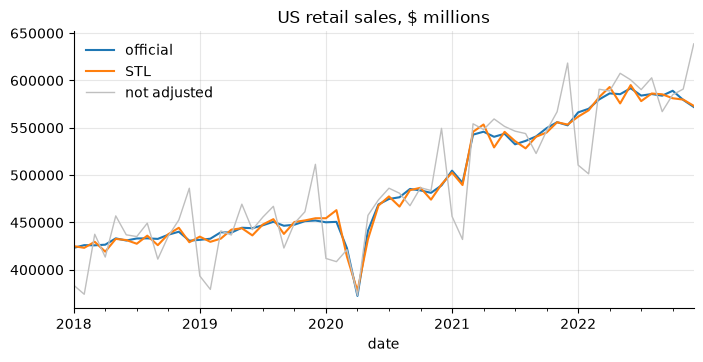

In [7]:
cmp = pd.DataFrame({"official": sa_official, "STL": sa_stl, "classical": sa_classic})
mm = 100 * np.log(cmp).diff()
print(mm.corr().round(3))
print(
    "RMS gap to official m/m (pp):",
    np.sqrt(((mm.sub(mm["official"], axis=0)) ** 2).mean()).round(2).to_dict(),
)

ax = cmp.loc["2018":"2022", ["official", "STL"]].plot()
nsa["2018":"2022"].plot(ax=ax, color="0.75", lw=1, label="not adjusted")
ax.set_title("US retail sales, $ millions")
ax.legend()

STL tracks the official adjustment closely in levels, but month-on-month
changes differ by 1.7 pp on average. Most of the gap is **calendar effects**:
a month with five Fridays and Saturdays sells more than one with five Mondays,
and Easter moves between March and April. STL cannot see those; X-13 can.

## Trading-day and Easter effects

You can get most of the way with STL by adding a regression on calendar
counts: weekday counts relative to Sundays, month length, and the share of
the eight days before Easter that fall in each month.

In [8]:
from dateutil.easter import easter

WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]


def calendar_regressors(index: pd.DatetimeIndex) -> pd.DataFrame:
    """Trading-day contrasts, month length and an Easter regressor, monthly."""
    days = pd.date_range(index[0], index[-1] + pd.offsets.MonthEnd(0), freq="D")
    counts = pd.crosstab(days.to_period("M"), days.day_name())
    X = counts[WEEKDAYS].sub(counts["Sunday"], axis=0)
    length = counts.sum(axis=1)
    X["length"] = length - length.mean()
    pre_easter = {
        yr: pd.date_range(easter(yr) - pd.Timedelta(days=8), periods=8)
        for yr in index.year.unique()
    }
    X["easter"] = [
        (pre_easter[p.year].month == p.month).mean() if p.month in (3, 4) else 0.0
        for p in X.index
    ]
    X.index = index
    return X.astype(float)


X = calendar_regressors(y.index)
calendar = pd.Series(0.0, index=y.index)
for _ in range(2):  # alternate: STL, then calendar regression
    stl_td = STL(y - calendar, period=12, seasonal=13, robust=True).fit()
    irregular = y - stl_td.seasonal - stl_td.trend
    reg = sm.OLS(irregular, sm.add_constant(X)).fit()
    calendar = X @ reg.params[X.columns]
sa_stl_td = np.exp(y - stl_td.seasonal - calendar)

mm2 = (
    100
    * np.log(
        pd.DataFrame(
            {"official": sa_official, "STL": sa_stl, "STL + calendar": sa_stl_td}
        )
    ).diff()
)
print(mm2.corr()["official"].round(2).to_dict())
print(
    "RMS gap (pp):",
    np.sqrt(mm2.sub(mm2["official"], axis=0).pow(2).mean()).round(2).to_dict(),
)

{'official': 1.0, 'STL': 0.71, 'STL + calendar': 0.87}
RMS gap (pp): {'official': 0.0, 'STL': 1.69, 'STL + calendar': 0.94}


```{admonition} In your projects
:class: tip
The same recipe is in the `econts` toolkit:

    from econts.seasonal import calendar_regressors, stl_adjust
    
    sa = stl_adjust(nsa, calendar=True)["sa"]
```

The calendar regression raises the m/m correlation with the official series
from 0.71 to 0.87 and nearly halves the gap. X-13 does this properly,
with the calendar effects estimated jointly in a regARIMA model.

## X-13ARIMA-SEATS

The US Census Bureau's program, the standard at statistical agencies. It
pre-adjusts with a regARIMA model (outliers, trading days, Easter), then
applies X-11 filters or SEATS. `statsmodels` wraps it, but you must download
the `x13as` executable from the
[Census Bureau](https://www.census.gov/data/software/x13as.html) and put it
on your `PATH` (or pass `x12path=`).

In [ ]:
# requires: x13as
from statsmodels.tsa.x13 import x13_arima_analysis

x13 = x13_arima_analysis(nsa["2010":"2019"], log=True, outlier=True, trading=True)
print(x13.results[:2000])  # the full X-13 diagnostic output
sa_x13 = x13.seasadj

If you work in R, the `seasonal` package is the most convenient X-13
interface, and JDemetra+ is the European (Eurostat/ECB) standard.

## Regression on seasonal dummies

For a quick, transparent adjustment inside a model, include month (or
quarter) dummies. This assumes **deterministic, constant** seasonality.

In [9]:
dummies = pd.get_dummies(y.index.month, prefix="m", drop_first=True, dtype=float)
dummies.index = y.index
trend = np.arange(len(y), dtype=float)
X = sm.add_constant(dummies.assign(t=trend, t2=trend**2))
fit = sm.OLS(y, X).fit()
seasonal_part = dummies @ fit.params[dummies.columns]
sa_dummies = np.exp(y - seasonal_part + seasonal_part.mean())

## Multiple seasonal periods: MSTL

High-frequency data can have several cycles: hourly electricity demand has a
daily (24) and a weekly (168) pattern; daily data have weekly and annual
cycles. `MSTL` peels them off one at a time. A simulated hourly example:

In [10]:
rng = np.random.default_rng(0)
hours = pd.date_range("2025-01-01", periods=24 * 7 * 8, freq="h")
h = np.arange(len(hours))
load_mw = (
    100
    + 0.01 * h
    + 15 * np.sin(2 * np.pi * h / 24)
    + 8 * np.sin(2 * np.pi * h / 168)
    + rng.normal(0, 2, len(h))
)
mstl = MSTL(pd.Series(load_mw, index=hours), periods=(24, 168)).fit()
print(mstl.seasonal.std().round(1))  # amplitude of each seasonal component

seasonal_24     10.6
seasonal_168     5.7
dtype: float64


## Year-on-year growth as a substitute

The y/y growth of an unadjusted series removes stable seasonality without
any model. It lags turning points by about six months and carries **base
effects** (a big move twelve months ago reappears, inverted, today).

In [11]:
yoy_nsa = 100 * nsa.pct_change(12)
yoy_sa = 100 * sa_official.pct_change(12)
print((yoy_nsa - yoy_sa).abs().describe().round(2))  # close, not identical

count    405.00
mean       0.94
std        0.89
min        0.00
25%        0.28
50%        0.56
75%        1.55
max        4.88
dtype: float64


## Pitfalls

* **Direct vs indirect** adjustment: adjusting the total is not the same as
  adding up adjusted components. Pick one and document it.
* **End-point revisions**: seasonal factors at the end of the sample are
  revised as new data arrive. Real-time analysis must use real-time vintages.
* **COVID**: 2020-21 broke many seasonal models. Use `robust=True`, or treat
  the period with outlier regressors (X-13) so it does not distort the
  seasonal factors for years after.
* Series with zero or negative values cannot be adjusted multiplicatively;
  use the additive model on levels.
* Quarterly data: `period=4`, and STL `seasonal=7` is a common choice.

## Summary

* Use the **official SA series** when one exists. Adjust yourself only
  for series nobody adjusts, or to build something new.
* Adjust **in logs** (multiplicative seasonality) for anything whose
  seasonal swing grows with its level.
* **STL** is the best quick tool in Python. **X-13ARIMA-SEATS** is what
  statistical offices use; it also handles trading-day and Easter effects.
* Never seasonally adjust an already-adjusted series, and never compute
  m/m changes on unadjusted data.

## Exercises

1. Compute the average monthly change of the unadjusted unemployment rate (`UNRATENSA`) by calendar month for 2010–2019, and test the month dummies jointly with an F-test. Which months carry the largest seasonal rise and fall, and why might that be?
2. Adjust `UNRATENSA` with STL (`period=12`, `robust=True`). Should you work in logs or levels for a rate? Compare the m/m changes of your series with the official `UNRATE` over 2010–2019 (correlation and RMS gap).
3. Aggregate unadjusted retail sales (`RSXFSN`) to quarters (chapter 3), adjust the quarterly series in logs with STL (`period=4`, `seasonal=7`), and compare its q/q growth with quarterly-aggregated `RSXFS`. Is quarterly adjustment closer to or further from the official series than the monthly STL of the chapter?
4. Fit STL to log `RSXFSN` with `robust=True` and with `robust=False`, and compare the seasonal factors for March and April in 2019 and 2022. How much does the 2020 lockdown contaminate later seasonal factors without the robust option?